# Week 7 - HAR: Exploratory Data Analysis (Univariate)

**Topic (record section d):** Look at one variable at a time - the class distribution (target) and the distribution of individual features.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_score, recall_score, f1_score)

# Local paths (the record used /content/... on Google Colab)
BASE = "data/har_raw/UCI HAR Dataset/"
X_train_path = BASE + "train/X_train.txt"
y_train_path = BASE + "train/y_train.txt"
X_test_path = BASE + "test/X_test.txt"
y_test_path = BASE + "test/y_test.txt"
features_path = BASE + "features.txt"
activities_path = BASE + "activity_labels.txt"

# Feature names (2nd column of features.txt)
features = pd.read_csv(features_path, sep=r"\s+", header=None)
feature_names = features.iloc[:, 1].tolist()

# Feature matrices: whitespace-separated numbers, no header
X_train = pd.read_csv(X_train_path, sep=r"\s+", header=None)
X_test = pd.read_csv(X_test_path, sep=r"\s+", header=None)

# The file has a few duplicated feature names (e.g. bandsEnergy), so we make them unique by suffixing the column index
seen, unique_names = {}, []
for i, n in enumerate(feature_names):
    unique_names.append(n if feature_names.count(n) == 1 else f"{n}_{i}")
feature_names = unique_names
X_train.columns = feature_names
X_test.columns = feature_names

# Labels
y_train = np.loadtxt(y_train_path, dtype=int)
y_test = np.loadtxt(y_test_path, dtype=int)

# Activity id -> name, keeping names that contain underscores/spaces
with open(activities_path, "r") as file:
    activity_names = {int(line.split(maxsplit=1)[0]): line.split(maxsplit=1)[1].strip() for line in file if line.strip()}

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)     # learn mean/std on TRAIN only
X_test_scaled = scaler.transform(X_test)           # reuse the train statistics on test
y_train_encoded = y_train - 1                      # ids 1-6 -> 0-5 (what Keras / sklearn metrics expect)
y_test_encoded = y_test - 1

print("Data loaded:", X_train.shape, X_test.shape)

Data loaded: (7352, 561) (2947, 561)


## Activity distribution
Are all 6 activities equally represented? Imbalanced classes can bias a classifier toward the majority class and make *accuracy* misleading.
`pd.Series(y_train).map(activity_names)` converts ids to names, `value_counts()` counts them.

LAYING                1407
STANDING              1374
SITTING               1286
WALKING               1226
WALKING_UPSTAIRS      1073
WALKING_DOWNSTAIRS     986
Name: count, dtype: int64


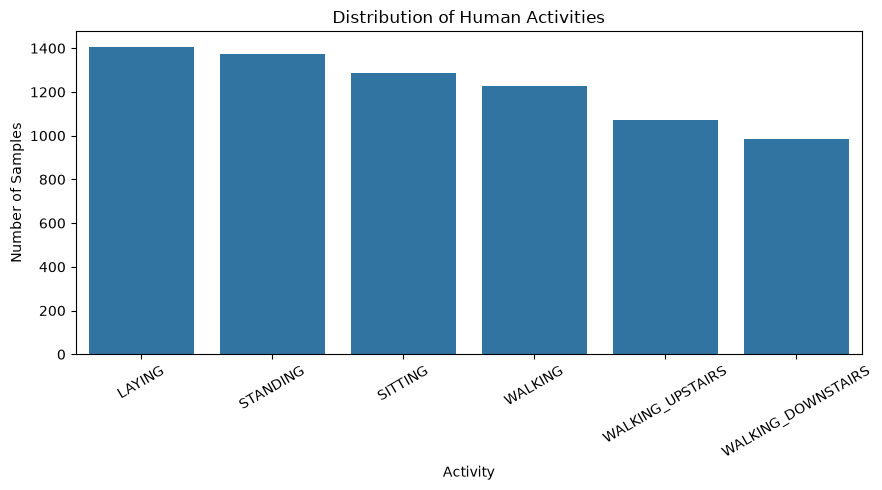

In [2]:
activity_counts = pd.Series(y_train).map(activity_names).value_counts()
print(activity_counts)

plt.figure(figsize=(9, 5))
sns.barplot(x=activity_counts.index, y=activity_counts.values)
plt.title("Distribution of Human Activities")
plt.xlabel("Activity"); plt.ylabel("Number of Samples")
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

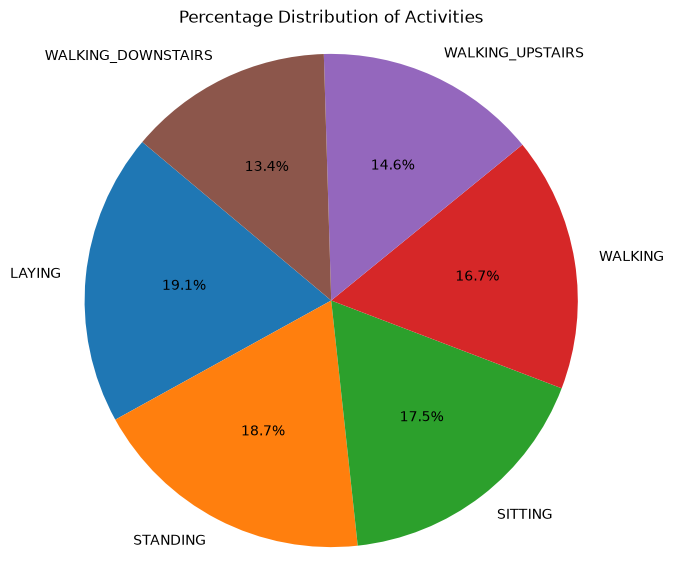

Largest / smallest class ratio: 1.43


In [3]:
plt.figure(figsize=(7, 7))
plt.pie(activity_counts.values, labels=activity_counts.index, autopct="%1.1f%%", startangle=140)
plt.title("Percentage Distribution of Activities")
plt.axis("equal"); plt.show()

print("Largest / smallest class ratio:", round(activity_counts.max() / activity_counts.min(), 2))

**Reading it:** the classes are close to balanced (roughly 14-19% each), so plain accuracy is a fair metric here.

## Distribution of a single feature
A histogram with a KDE (smoothed density curve) for the first feature, `tBodyAcc-mean()-X` (average body acceleration along X).

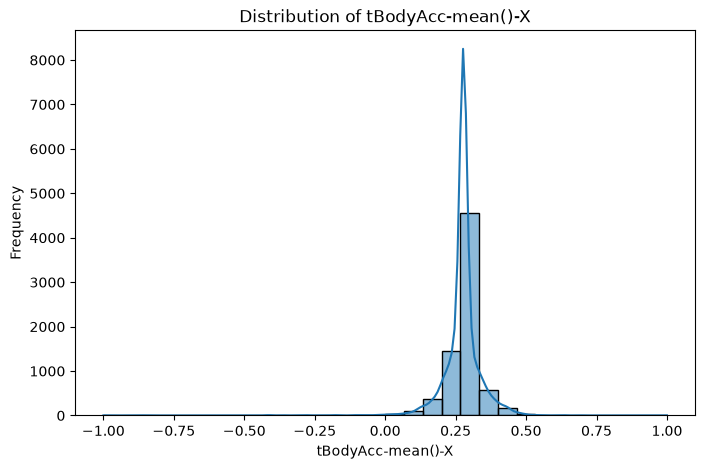

count    7352.0000
mean        0.2745
std         0.0703
min        -1.0000
25%         0.2630
50%         0.2772
75%         0.2885
max         1.0000
Name: tBodyAcc-mean()-X, dtype: float64


In [4]:
feature = feature_names[0]
plt.figure(figsize=(8, 5))
sns.histplot(X_train[feature], bins=30, kde=True)
plt.title(f"Distribution of {feature}")
plt.xlabel(feature); plt.ylabel("Frequency"); plt.show()
print(X_train[feature].describe().round(4))

## Extension: does a feature separate the activities?
The most informative thing about a feature is whether its distribution *differs between classes*. A boxplot of the feature per activity shows this - features that separate classes well are valuable for classifiers.

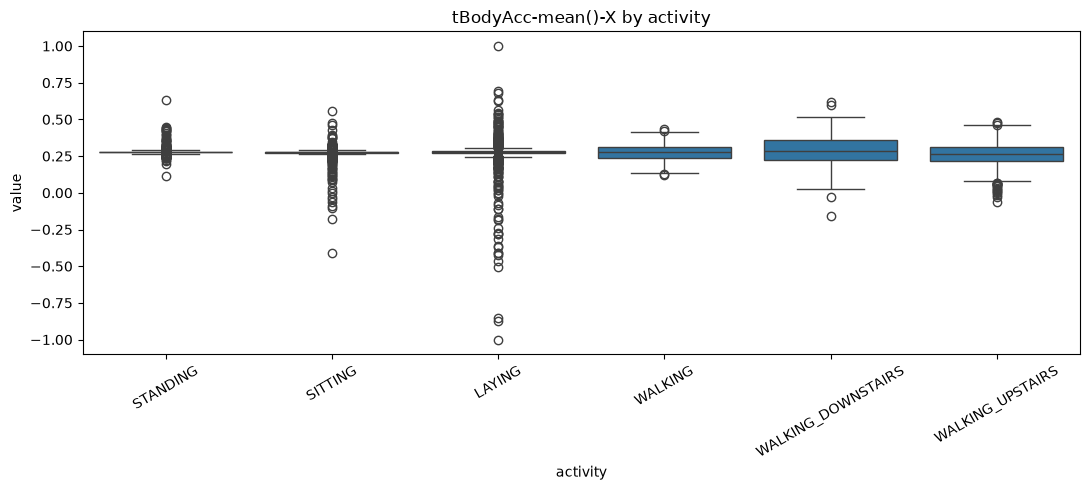

In [5]:
plt.figure(figsize=(11, 5))
tmp = pd.DataFrame({"value": X_train[feature].values, "activity": pd.Series(y_train).map(activity_names)})
sns.boxplot(data=tmp, x="activity", y="value")
plt.title(f"{feature} by activity"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

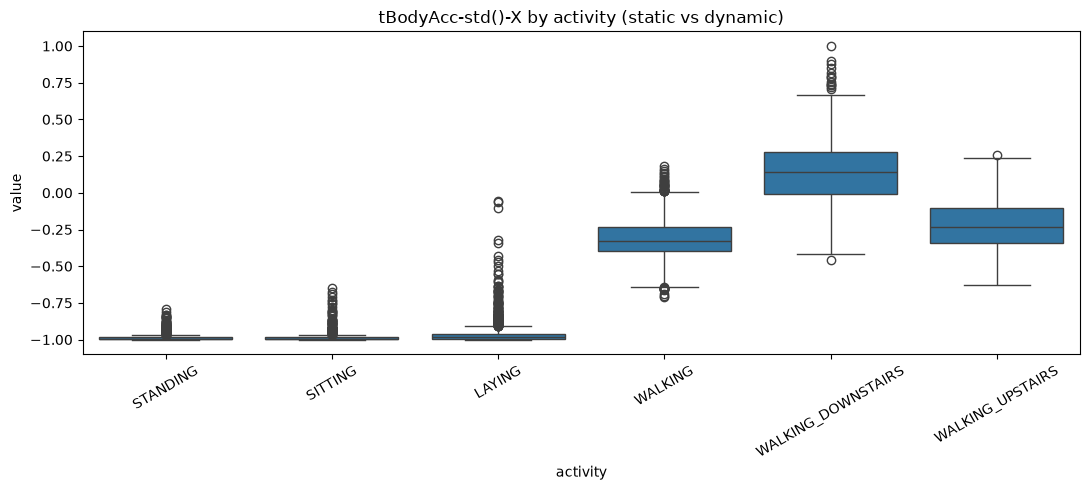

In [6]:
# A feature that usually separates static vs moving activities very well: the std of body acceleration
std_feature = "tBodyAcc-std()-X"
plt.figure(figsize=(11, 5))
tmp = pd.DataFrame({"value": X_train[std_feature].values, "activity": pd.Series(y_train).map(activity_names)})
sns.boxplot(data=tmp, x="activity", y="value")
plt.title(f"{std_feature} by activity (static vs dynamic)"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

**Reading it:** `tBodyAcc-std()-X` is very low for sitting/standing/laying (little movement) and high for the three walking activities - which is why even simple models separate "moving" from "still" easily. The hard part is telling *sitting* from *standing* and the 3 walking types from each other.

## Summary
* Classes are near-balanced -> accuracy is an acceptable metric.
* Single-feature distributions show how informative each sensor feature is.